<div dir="rtl">

# תוסף בזמן: מחברת EDA (אבן דרך M2)

**השאלה:** האם יש בנתונים סיגנל, כלומר קשר בין העמודות לבין עמודת התשובה, שמודל יוכל ללמוד ב-M3?

- **משתמש:** סטודנטים ומתאמנים צעירים שנוטלים תוספי תזונה.
- **מה נחזה (y):** `vitd_low`: האם רמת ויטמין D בדם נמוכה (25(OH)D מתחת ל-50 nmol/L). סיווג בינארי (0/1).
  - y משני: `vitd_nmol_l` (הרמה עצמה, רגרסיה), ו-`iron_low` (פריטין מתחת ל-15 ng/mL).
- **למה זה עוזר למשתמש:** האפליקציה תגיד לו אם כדאי לבקש בדיקת ויטמין D לפני שהוא קונה תוסף "ליתר ביטחון".
- **הנתונים:** NHANES של ה-CDC, שני סבבים (2017–2018 ו-2021–2023), אחרי ניקוי: קובץ `data/nhanes_supplements_vitd_clean.csv`. הניקוי עצמו נעשה ב-`scripts/clean_data.py`, וכל שלב מתועד ב-`data/cleaning_log.csv`.

המחברת עונה על ארבע השאלות: **(1) סוגי העמודות, (2) איכות, (3) התפלגויות, (4) קורלציה מול y, כולל בדיקת דליפה.** בסוף: baseline ותובנה.
מתחת לכל גרף כתובה מסקנה. כל המספרים מחושבים כאן מהקובץ.

</div>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path("data") / "nhanes_supplements_vitd_clean.csv"
df = pd.read_csv(DATA)
print(f"{len(df):,} rows x {df.shape[1]} columns")
df.head()

9,626 rows x 27 columns


,seqn,cycle,age_years,sex,race_ethnicity,exam_season,bmi,weight_kg,ferritin_ng_ml,takes_supplement,n_supplements,supp_vitd_mcg,supp_vitc_mg,supp_magnesium_mg,supp_iron_mg,supp_zinc_mg,supp_b12_mcg,supp_calcium_mg,takes_creatine,takes_probiotic,takes_fish_oil,takes_multivitamin,takes_protein_powder,vitd_nmol_l,vitd_status,vitd_low,iron_low
0,93705,2017-2018,66,female,Non-Hispanic Black,May-Oct,31.7,79.5,28.7,1,8,20.56,616.67,100.00,0.73,15.83,114.22,211.67,0,0,0,1,0,89.9,sufficient (>=50),0,0.0
1,93706,2017-2018,18,male,Non-Hispanic Asian,May-Oct,21.5,66.3,284.0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,53.8,sufficient (>=50),0,0.0
2,93708,2017-2018,66,female,Non-Hispanic Asian,May-Oct,23.7,53.5,109.0,1,3,25.00,60.00,50.00,0.00,11.00,25.00,820.00,0,0,1,1,0,116.0,sufficient (>=50),0,0.0
3,93709,2017-2018,75,female,Non-Hispanic Black,Nov-Apr,38.9,88.8,129.0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,72.8,sufficient (>=50),0,0.0
4,93711,2017-2018,56,male,Non-Hispanic Asian,May-Oct,21.3,62.1,40.6,1,9,25.00,150.00,186.67,0.00,0.00,2515.00,35.00,0,1,1,0,0,165.0,sufficient (>=50),0,0.0


<div dir="rtl">

## שאלה 1: סוגי העמודות

לכל עמודה קובעים מה היא באמת, לא רק מה pandas חושב:
- **מזהה:** `seqn`. אין טעם לחשב עליו ממוצע או קורלציה.
- **קטגוריה:** מין, מוצא, עונת הבדיקה, סבב הסקר.
- **בוליאני (0/1):** האם נוטל תוסף, או סוג מוצר מסוים.
- **מספר עם משמעות של כמות:** גיל, BMI, משקל, מינונים מתוספים.
- **עמודות תשובה (y), ועמודות שנגזרו מהן.**

</div>

In [2]:
kind = {
    "seqn": "ID",
    "cycle": "category", "sex": "category", "race_ethnicity": "category", "exam_season": "category",
    "vitd_nmol_l": "TARGET (numeric)", "vitd_low": "TARGET (0/1)", "iron_low": "TARGET 2 (0/1)",
    "vitd_status": "derived from target", "ferritin_ng_ml": "numeric (source of iron_low)",
}
for c in df.columns:
    if c in kind:
        continue
    kind[c] = "binary 0/1" if set(df[c].dropna().unique()) <= {0, 1} else "numeric (amount)"

types = pd.DataFrame({
    "pandas dtype": df.dtypes.astype(str),
    "what it really is": pd.Series(kind),
    "unique values": df.nunique(),
    "example": df.iloc[0],
}).loc[df.columns]
types

,pandas dtype,what it really is,unique values,example
seqn,int64,ID,9626,93705
cycle,str,category,2,2017-2018
age_years,int64,numeric (amount),63,66
sex,str,category,2,female
race_ethnicity,str,category,6,Non-Hispanic Black
exam_season,str,category,2,May-Oct
bmi,float64,numeric (amount),445,31.7
weight_kg,float64,numeric (amount),1128,79.5
ferritin_ng_ml,float64,numeric (source of iron_low),1516,28.7
takes_supplement,int64,binary 0/1,2,1


In [3]:
types["what it really is"].value_counts()

what it really is
numeric (amount)                11
binary 0/1                       6
category                         4
ID                               1
numeric (source of iron_low)     1
TARGET (numeric)                 1
derived from target              1
TARGET (0/1)                     1
TARGET 2 (0/1)                   1
Name: count, dtype: int64

<div dir="rtl">

**מסקנה:**
- `seqn` נראה כמו מספר, אבל הוא מזהה. לא מכניסים אותו למודל.
- `exam_season` ו-`cycle` הם קטגוריות, ומין ומוצא נשמרו כטקסט. לפני המודל נהפוך אותם ל-0/1 (one-hot).
- עמודות `takes_*` הן 0/1 ולכן אפשר להשתמש בהן כמו שהן.
- `vitd_status` ו-`vitd_low` לא נמדדו בנפרד. הן **חושבו** מתוך `vitd_nmol_l`, וכך גם `iron_low` חושבה מתוך `ferritin_ng_ml`. נבדוק את זה בשאלה 4 (דליפה).

</div>

<div dir="rtl">

## שאלה 2: איכות הנתונים

בודקים ערכים חסרים, 0 שהוא בעצם חסר, כפילויות, ערכים חריגים או לא הגיוניים. על כל בעיה מחליטים מה עושים.

</div>

In [4]:
missing = df.isna().sum()
print("Missing values per column (only columns with missing):")
print(missing[missing > 0])
print()
print("Duplicate seqn:", df.seqn.duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

Missing values per column (only columns with missing):
ferritin_ng_ml    3634
iron_low          3634
dtype: int64

Duplicate seqn: 0
Fully duplicated rows: 0


In [5]:
# Ferritin was not measured for everyone: who is missing?
m = df.assign(ferritin_missing=df.ferritin_ng_ml.isna())
pd.crosstab([m.cycle, m.sex], m.ferritin_missing, margins=True)

ferritin_missing  False  True   All
cycle     sex                      
2017-2018 female   2606    11  2617
          male     2462    11  2473
2021-2023 female    924  1571  2495
          male        0  2041  2041
All                5992  3634  9626

<div dir="rtl">

**מסקנה:**
- אין כפילויות. החוסרים היחידים הם בפריטין (`ferritin_ng_ml`), ולכן גם ב-`iron_low`: 3,634 שורות.
- זה לא מקרי. ב-2021–2023 ה-CDC מדד פריטין רק לנשים עד גיל 49, ולכן בסבב הזה חסרים כל הגברים (2,041) ורוב הנשים (1,571). ב-2017–2018 חסרים רק 22.
- **ההחלטה:** לא ממלאים ולא מוחקים. ויטמין D נמדד אצלם, ולכן השורות נשארות למודל של ויטמין D. ניתוח הברזל משתמש רק ב-5,992 השורות שבהן הפריטין נמדד.

</div>

In [6]:
dose_cols = [c for c in df.columns if c.startswith("supp_")]
zeros = (df[dose_cols] == 0).mean().mul(100).round(1).rename("% zero")
print("Share of zeros in supplement doses:")
print(zeros)
print()
print("Takes no supplement at all:", (df.takes_supplement == 0).sum())
odd = df[(df.takes_supplement == 0) & (df[dose_cols].sum(axis=1) > 0)]
print("Rows where takes_supplement==0 but some dose > 0:", len(odd))
print("...which doses are non-zero in those rows (count of people):")
print((odd[dose_cols] > 0).sum())

Share of zeros in supplement doses:
supp_vitd_mcg        56.0
supp_vitc_mg         61.8
supp_magnesium_mg    72.5
supp_iron_mg         83.4
supp_zinc_mg         67.8
supp_b12_mcg         63.8
supp_calcium_mg      58.6
Name: % zero, dtype: float64

Takes no supplement at all: 3922
Rows where takes_supplement==0 but some dose > 0: 466
...which doses are non-zero in those rows (count of people):
supp_vitd_mcg          0
supp_vitc_mg           0
supp_magnesium_mg     78
supp_iron_mg           0
supp_zinc_mg           0
supp_b12_mcg           0
supp_calcium_mg      446
dtype: int64


<div dir="rtl">

**מסקנה: 0 במינון הוא ערך אמיתי, לא חסר.**
- ברוב השורות המינון הוא 0, כי רוב האנשים לא נוטלים את החומר הזה בתוסף.
- בקובץ המקורי התאים האלה היו ריקים. מילאנו 0 ("אין צריכה מתוספים") ולא ממוצע, כי ממוצע היה ממציא צריכה שלא קיימת.
- **בעיה שמצאנו:** 466 נבדקים ענו "לא נוטל תוסף", ובכל זאת יש להם מינון. אצל כולם זה רק **סידן ומגנזיום**, ואף פעם לא ויטמין D.
  - ההסבר הסביר: NHANES סופר בצריכה הכוללת גם סידן ומגנזיום מתרופות נוגדות חומצה (כמו Tums), שאנשים לא רואים בהן "תוסף".
  - **ההחלטה:** משאירים. זה לא משפיע על ויטמין D, שהוא ה-y שלנו. צריך לבדוק את זה בתיעוד של `DSQTOT` לפני שמשתמשים בסידן במודל.

</div>

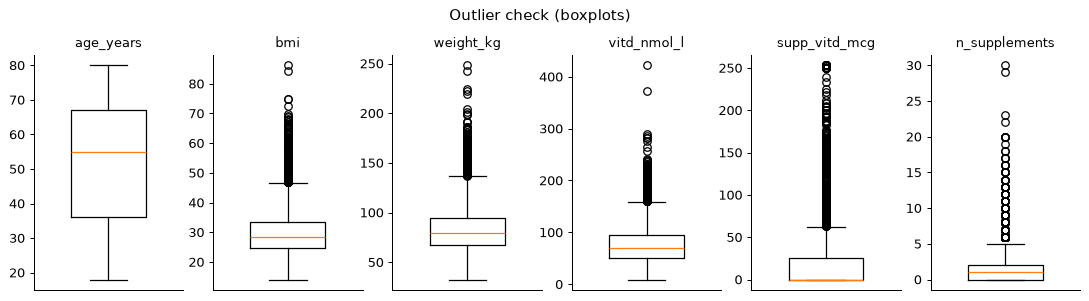

age_years == 80 (NHANES top-codes 80+): 572
vitd_nmol_l > 250: 9 | max: 422.0
BMI range: 14.1 - 86.2


In [7]:
cols = ["age_years", "bmi", "weight_kg", "vitd_nmol_l", "supp_vitd_mcg", "n_supplements"]
fig, axes = plt.subplots(1, len(cols), figsize=(15, 3.4))
for ax, c in zip(axes, cols):
    ax.boxplot(df[c].dropna(), widths=0.5)
    ax.set_title(c, fontsize=10)
    ax.set_xticks([])
fig.suptitle("Outlier check (boxplots)", y=1.03)
plt.show()

print("age_years == 80 (NHANES top-codes 80+):", (df.age_years == 80).sum())
print("vitd_nmol_l > 250:", (df.vitd_nmol_l > 250).sum(), "| max:", df.vitd_nmol_l.max())
print("BMI range:", df.bmi.min(), "-", df.bmi.max())

<div dir="rtl">

**מסקנה:**
- **גיל:** יש עמודה צפופה ב-80. זה לא באג: NHANES מקודד כל מי שבן 80 ומעלה כ-80 (572 נבדקים). משאירים, וזוכרים שגיל 80 פירושו "80 ומעלה".
- **ויטמין D:** 9 נבדקים מעל 250 nmol/L (מקסימום 422). זה גבוה מאוד אבל אפשרי אצל מי שלוקח מינונים גבוהים. **לא חתכנו את משתנה היעד**, כדי לא לשנות את התשובה.
- **מינונים ופריטין:** נחתכו כבר בניקוי באחוזון 99, ולכן הערכים הקיצוניים לא מעוותים את הגרפים (269 תאים).
- **BMI:** בין 14 ל-86. קיצוני אבל אפשרי בסקר בריאות, ולכן משאירים.

</div>

In [8]:
log = pd.read_csv("data/cleaning_log.csv")
log[["step", "rows_before", "rows_after", "rows_affected"]]

,step,rows_before,rows_after,rows_affected
0,combine_cycles_and_duplicates,21187,21187,0
1,adults_only,21187,14009,7178
2,drop_pregnant,14009,13913,96
3,drop_missing_target,13913,10966,2947
4,drop_no_supplement_answer,10966,9750,1216
5,drop_missing_bmi,9750,9626,124
6,mark_missing_ferritin,9626,9626,3634
7,fill_doses_with_zero,9626,9626,44640
8,types_and_labels,9626,9626,9626
9,clip_outliers_p99,9626,9626,269


<div dir="rtl">

**מסקנה: כך הגענו מ-21,187 נבדקים ל-9,626.**
- רוב ההסרה היא של ילדים ושל מי שלא נמדד להם ויטמין D, כלומר שורות שאין בהן y.
- נשארו **9,626 שורות נקיות**, הרבה מעל המינימום של 300.
- הסיבה לכל שלב כתובה ב-`data/cleaning_log.csv` וב-README.

</div>

<div dir="rtl">

## שאלה 3: התפלגויות, ובמיוחד של עמודת התשובה

</div>

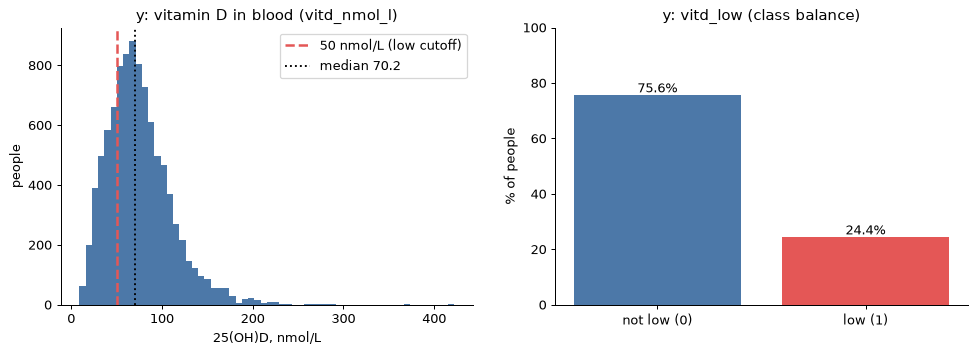

count    9626.0
mean       75.1
std        35.5
min         9.1
25%        50.6
50%        70.2
75%        94.0
max       422.0
Name: vitd_nmol_l, dtype: float64

vitd_status
sufficient (>=50)       7279
inadequate (30-49.9)    1681
deficient (<30)          666
Name: count, dtype: int64


In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.hist(df.vitd_nmol_l, bins=60, color="#4C78A8")
a1.axvline(50, color="#E45756", ls="--", lw=2, label="50 nmol/L (low cutoff)")
a1.axvline(df.vitd_nmol_l.median(), color="black", ls=":", lw=1.5, label=f"median {df.vitd_nmol_l.median():.1f}")
a1.set_title("y: vitamin D in blood (vitd_nmol_l)")
a1.set_xlabel("25(OH)D, nmol/L")
a1.set_ylabel("people")
a1.legend()

share = df.vitd_low.value_counts(normalize=True).sort_index().mul(100)
a2.bar(["not low (0)", "low (1)"], share.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(share.values):
    a2.text(i, v + 1, f"{v:.1f}%", ha="center")
a2.set_title("y: vitd_low (class balance)")
a2.set_ylabel("% of people")
a2.set_ylim(0, 100)
plt.show()

print(df.vitd_nmol_l.describe().round(1))
print()
print(df.vitd_status.value_counts())

<div dir="rtl">

**מסקנה:**
- הרמה בדם מוטה ימינה: רוב האנשים בין 50 ל-95 nmol/L, עם זנב ארוך של רמות גבוהות. החציון (70.2) נמוך מהממוצע (75.1).
- **24.4% נמצאים ברמה נמוכה** (מתחת ל-50 nmol/L). כלומר הנתונים **לא מאוזנים**: על כל אדם עם רמה נמוכה יש בערך שלושה עם רמה תקינה.
- המשמעות ל-M3: מודל שתמיד עונה "לא נמוך" כבר יקבל 75.6% דיוק בלי ללמוד כלום. לכן נמדוד גם recall, כלומר כמה מהנמוכים באמת נמצאו.

</div>

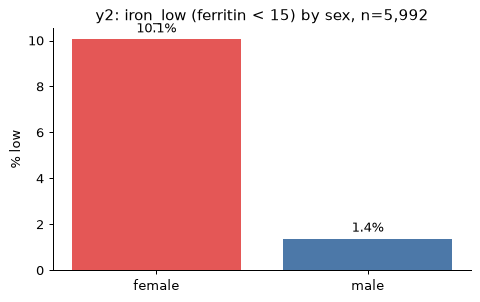

iron_low overall: 6.5%


In [10]:
iron = df.dropna(subset=["iron_low"])
tab = iron.groupby("sex").iron_low.mean().mul(100)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(tab.index, tab.values, color=["#E45756", "#4C78A8"])
for i, v in enumerate(tab.values):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center")
ax.set_title(f"y2: iron_low (ferritin < 15) by sex, n={len(iron):,}")
ax.set_ylabel("% low")
plt.show()
print(f"iron_low overall: {iron.iron_low.mean() * 100:.1f}%")

<div dir="rtl">

**מסקנה:**
- רק **6.5%** מהנבדקים עם מאגרי ברזל נמוכים, ולכן ה-y הזה עוד יותר לא מאוזן.
- רוב המקרים הם נשים: 10.1% מהנשים לעומת 1.4% מהגברים.
- בגלל החוסרים והחוסר באיזון, **ה-y הראשי שלנו הוא ויטמין D**, וברזל הוא הרחבה אם יהיה זמן.

</div>

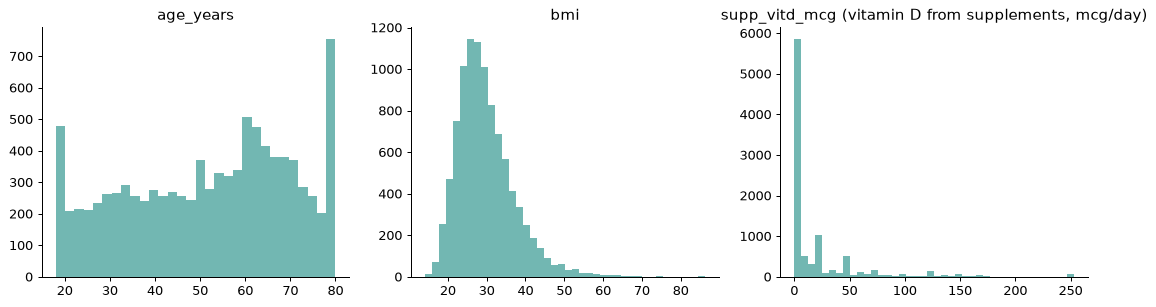

No vitamin D from supplements: 56.0%


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(df.age_years, bins=30, color="#72B7B2")
axes[0].set_title("age_years")
axes[1].hist(df.bmi, bins=40, color="#72B7B2")
axes[1].set_title("bmi")
axes[2].hist(df.supp_vitd_mcg, bins=40, color="#72B7B2")
axes[2].set_title("supp_vitd_mcg (vitamin D from supplements, mcg/day)")
plt.show()
print(f"No vitamin D from supplements: {(df.supp_vitd_mcg == 0).mean() * 100:.1f}%")

<div dir="rtl">

**מסקנה:**
- **גיל:** פרוס על כל טווח המבוגרים, עם עמודה ב-80 (הקידוד של NHANES).
- **BMI:** סביב 28–29, כלומר רוב המדגם האמריקאי במשקל עודף.
- **ויטמין D מתוספים:** ל-56% אין בכלל ויטמין D מתוספים, ולשאר יש מינונים מפוזרים. כשההתפלגות כזו, עדיף להסתכל על **קבוצות מינון** ולא רק על ממוצע, וזה מה שנעשה בשאלה 4.

</div>

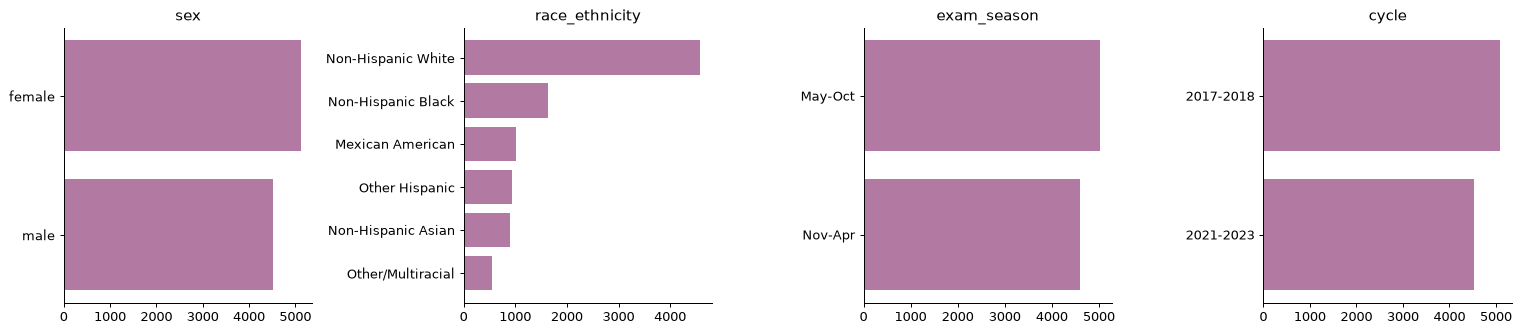

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, c in zip(axes, ["sex", "race_ethnicity", "exam_season", "cycle"]):
    vc = df[c].value_counts()
    ax.barh(vc.index, vc.values, color="#B279A2")
    ax.set_title(c)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

<div dir="rtl">

**מסקנה:**
- מין, עונה וסבב מאוזנים בערך.
- במוצא, Non-Hispanic White היא הקבוצה הגדולה (כמעט חצי). Other/Multiracial הכי קטנה (546), אבל עדיין מספיק גדולה לניתוח.
- **אין קבוצה עם פחות מ-30 נבדקים**, ולכן אפשר להשוות בין כולן.

</div>

<div dir="rtl">

## שאלה 4: קורלציה מול עמודת התשובה, ובדיקת דליפה

קורלציה היא מספר בין 1- ל-1. קרוב ל-0 פירושו שאין קשר. קורלציה גבוהה מאוד (למשל 0.98) היא חשד ל**דליפה**: העמודה כבר מכילה את התשובה.

</div>

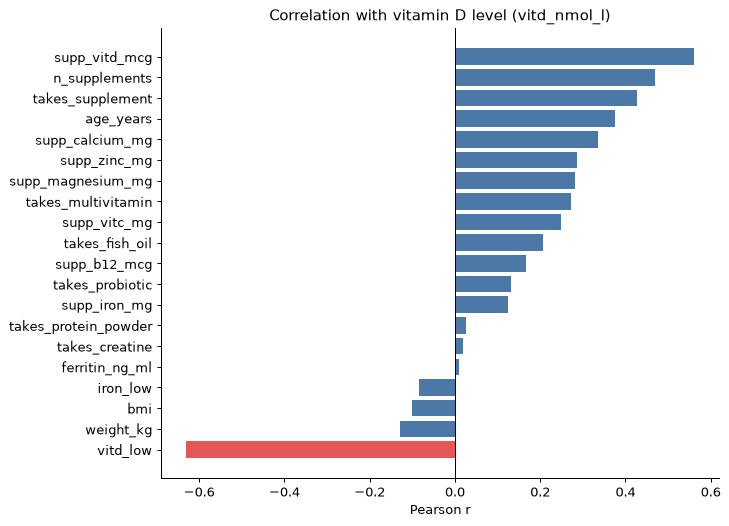

supp_vitd_mcg           0.560
n_supplements           0.469
takes_supplement        0.427
age_years               0.376
supp_calcium_mg         0.336
supp_zinc_mg            0.287
supp_magnesium_mg       0.282
takes_multivitamin      0.272
supp_vitc_mg            0.249
takes_fish_oil          0.207
supp_b12_mcg            0.167
takes_probiotic         0.131
supp_iron_mg            0.125
takes_protein_powder    0.026
takes_creatine          0.018
ferritin_ng_ml          0.009
iron_low               -0.085
bmi                    -0.100
weight_kg              -0.128
vitd_low               -0.630
dtype: float64

In [13]:
num = df.select_dtypes("number").drop(columns=["seqn", "vitd_nmol_l"])
corr = num.corrwith(df.vitd_nmol_l).sort_values()
colors = ["#E45756" if c in ("vitd_low",) else "#4C78A8" for c in corr.index]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlation with vitamin D level (vitd_nmol_l)")
ax.set_xlabel("Pearson r")
plt.show()
corr.round(3).sort_values(ascending=False)

<div dir="rtl">

**מסקנה: יש סיגנל.**
- הקשר החזק ביותר הוא **ויטמין D מתוספים** (r = 0.56). אחריו מספר התוספים (0.47), האם נוטל תוסף כלשהו (0.43) וגיל (0.38).
- משקל ו-BMI מראים קשר הפוך חלש: ככל שה-BMI גבוה יותר, הרמה נמוכה מעט יותר.
- פריטין, קריאטין ואבקת חלבון כמעט לא קשורים לרמת ויטמין D (r קרוב ל-0).
- **`vitd_low` (באדום) היא לא מאפיין.** היא נגזרה מ-y (ראו בדיקת הדליפה למטה).
- חשוב: זה **קשר, לא סיבתיות**. הנתונים הם מדגם חתך.

</div>

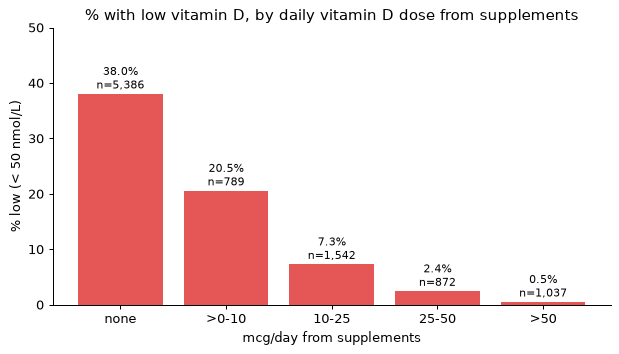

In [14]:
groups = pd.cut(df.supp_vitd_mcg, [-1, 0, 10, 25, 50, 10_000],
                labels=["none", ">0-10", "10-25", "25-50", ">50"])
t = df.groupby(groups, observed=True).vitd_low.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(t.index.astype(str), t["mean"] * 100, color="#E45756")
for i, (p, n) in enumerate(zip(t["mean"], t["size"])):
    ax.text(i, p * 100 + 1, f"{p * 100:.1f}%\nn={n:,}", ha="center", fontsize=9)
ax.set_title("% with low vitamin D, by daily vitamin D dose from supplements")
ax.set_xlabel("mcg/day from supplements")
ax.set_ylabel("% low (< 50 nmol/L)")
ax.set_ylim(0, 50)
plt.show()

<div dir="rtl">

**מסקנה: זה הגרף המרכזי של הפרויקט.**
- בקרב מי שלא לוקחים ויטמין D מתוספים, **38%** ברמה נמוכה.
- בקרב מי שלוקחים 10–25 מק"ג ביום, רק **7%**.
- ומעל 50 מק"ג, פחות מ-**1%**.
- הירידה עקבית ובכל קבוצה יש מאות נבדקים, ולכן זה לא מקרי. למודל יהיה מה ללמוד מהעמודה הזו.

</div>

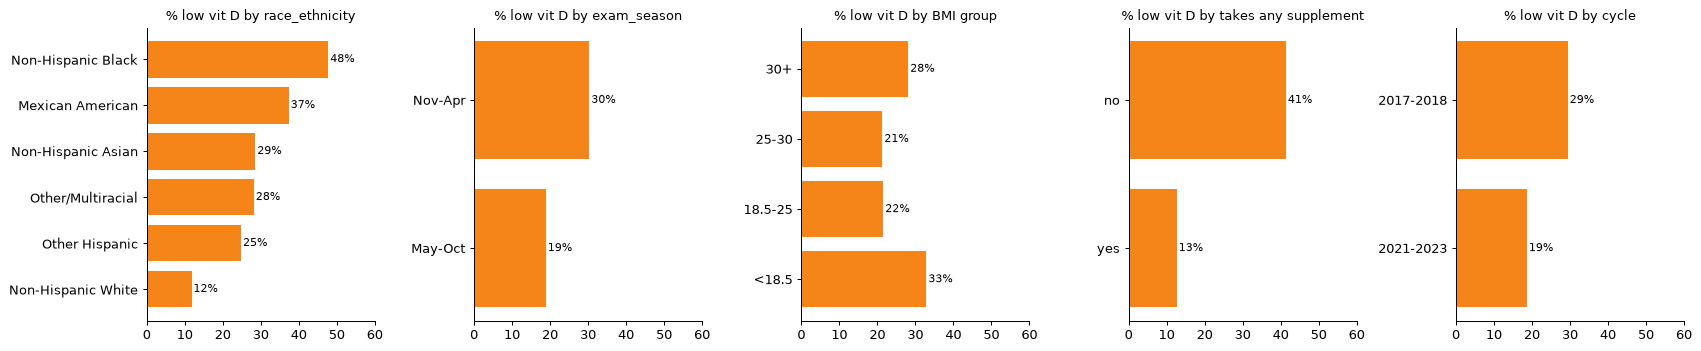

In [15]:
def pct_low(col, order=None):
    s = df.groupby(col, observed=True).vitd_low.mean().mul(100)
    return s.reindex(order) if order else s.sort_values()

bmi_g = pd.cut(df.bmi, [0, 18.5, 25, 30, 100], labels=["<18.5", "18.5-25", "25-30", "30+"])
panels = [
    ("race_ethnicity", pct_low("race_ethnicity")),
    ("exam_season", pct_low("exam_season")),
    ("BMI group", df.groupby(bmi_g, observed=True).vitd_low.mean().mul(100)),
    ("takes any supplement", pct_low("takes_supplement").rename({0: "no", 1: "yes"})),
    ("cycle", pct_low("cycle")),
]
fig, axes = plt.subplots(1, 5, figsize=(19, 4))
for ax, (title, s) in zip(axes, panels):
    ax.barh(s.index.astype(str), s.values, color="#F58518")
    for i, v in enumerate(s.values):
        ax.text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=9)
    ax.set_title(f"% low vit D by {title}", fontsize=10)
    ax.set_xlim(0, 60)
plt.tight_layout()
plt.show()

<div dir="rtl">

**מסקנה: גם הקטגוריות נושאות סיגנל.**
- **מוצא:** הפער הגדול ביותר. 48% מה-Non-Hispanic Black ברמה נמוכה, לעומת 12% מה-Non-Hispanic White. עור כהה מייצר פחות ויטמין D מהשמש.
- **עונה:** 30% בחורף (נובמבר–אפריל) לעומת 19% בקיץ.
- **BMI:** מעל 30, 28% ברמה נמוכה, לעומת 21–22% בטווח 18.5–30. גם בתת-משקל יש 33%, אבל זו קבוצה קטנה (158 נבדקים).
- **נוטל תוסף כלשהו:** 41% ברמה נמוכה בקרב מי שלא נוטלים, לעומת 13% בקרב הנוטלים.
- **סבב:** 29% ב-2017–2018 לעומת 19% ב-2021–2023. לכן נכניס את `cycle` כמאפיין, ובחלוקה ל-train/test נקפיד ששני הסבבים מופיעים בשני החלקים.
- מין כמעט לא משפיע (23% בנשים, 26% בגברים).

</div>

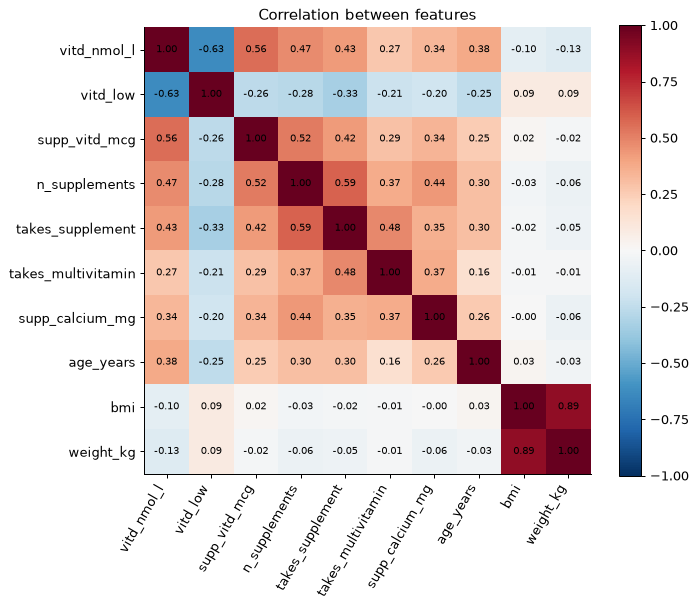

In [16]:
corr_mat = df[["vitd_nmol_l", "vitd_low", "supp_vitd_mcg", "n_supplements", "takes_supplement",
               "takes_multivitamin", "supp_calcium_mg", "age_years", "bmi", "weight_kg"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr_mat, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_mat)), corr_mat.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr_mat)), corr_mat.columns)
for i in range(len(corr_mat)):
    for j in range(len(corr_mat)):
        ax.text(j, i, f"{corr_mat.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlation between features")
plt.show()

<div dir="rtl">

**מסקנה: חלק מהמאפיינים קשורים זה לזה.**
- `bmi` ו-`weight_kg` כמעט אותו דבר (r = 0.89), ולכן מספיק אחד מהם. נשאיר את BMI, שהוא המדד המקובל.
- `takes_supplement`, `n_supplements`, `takes_multivitamin` ו-`supp_vitd_mcg` קשורים זה לזה, כי מי שלוקח מולטי-ויטמין מקבל ממנו גם ויטמין D. זה לא אסור, אבל צריך לזכור שהם מספרים חלק מאותו סיפור.

</div>

<div dir="rtl">

### בדיקת דליפה (leakage)

שואלים על כל עמודה: **האם היא הייתה ידועה לנו לפני שידענו את התשובה?** אם היא נבנתה מתוך התשובה, היא דליפה. המודל "ירמה" ויקבל ציון מושלם בבדיקה, אבל לא יעבוד על משתמש אמיתי.

</div>

In [17]:
# 1) Columns derived from the target: they reproduce it perfectly
rule_vitd = (df.vitd_nmol_l < 50).astype(int)
print("vitd_low == (vitd_nmol_l < 50):", (rule_vitd == df.vitd_low).mean() * 100, "% of rows")
print(df.groupby("vitd_status").vitd_nmol_l.agg(["min", "max"]))
print()
iron = df.dropna(subset=["iron_low"])
rule_iron = (iron.ferritin_ng_ml < 15).astype(int)
print("iron_low == (ferritin < 15):", (rule_iron == iron.iron_low).mean() * 100, "% of rows")
print("Pearson r(ferritin, iron_low):", round(iron.ferritin_ng_ml.corr(iron.iron_low), 3))

vitd_low == (vitd_nmol_l < 50): 100.0 % of rows
                        min    max
vitd_status                       
deficient (<30)        9.13   29.9
inadequate (30-49.9)  30.00   49.9
sufficient (>=50)     50.00  422.0

iron_low == (ferritin < 15): 100.0 % of rows
Pearson r(ferritin, iron_low): -0.236


In [18]:
# 2) Any feature with suspiciously high correlation (|r| > 0.9) to the target?
feat = df.select_dtypes("number").drop(columns=["vitd_nmol_l", "vitd_low", "iron_low"])
r = feat.corrwith(df.vitd_nmol_l).abs().sort_values(ascending=False)
print("Highest |r| with vitd_nmol_l among real features:")
print(r.head(5).round(3))
print("Features with |r| > 0.9:", list(r[r > 0.9].index) or "none")
print()
# 3) The ID column: should be meaningless, but is it?
print("r(seqn, vitd_nmol_l):", round(df.seqn.corr(df.vitd_nmol_l), 3))
print(df.groupby("cycle").seqn.agg(["min", "max"]))

Highest |r| with vitd_nmol_l among real features:
supp_vitd_mcg       0.560
n_supplements       0.469
takes_supplement    0.427
age_years           0.376
supp_calcium_mg     0.336
dtype: float64
Features with |r| > 0.9: none

r(seqn, vitd_nmol_l): 0.202
              min     max
cycle                    
2017-2018   93705  102956
2021-2023  130378  142310


<div dir="rtl">

**מסקנה: מה מוציאים מהמודל, ולמה.**

| עמודה | למה זו דליפה או בעיה | מה עושים ב-M3 |
|---|---|---|
| `vitd_low`, `vitd_status` | חושבו מתוך `vitd_nmol_l`. הן משחזרות את התשובה ב-100% מהשורות | מוציאים. הן התשובה, לא מאפיין |
| `ferritin_ng_ml` (במודל הברזל) | `iron_low` הוא פשוט "פריטין מתחת ל-15", 100% התאמה | מוציאים כשחוזים ברזל |
| `seqn` | מזהה. ובכל זאת יש לו r = 0.20 עם ויטמין D, כי המספרים של סבב 2021–2023 גבוהים יותר, וגם הרמות גבוהות יותר | מוציאים. את מידע הסבב נותנים בגלוי דרך `cycle` |

- **לקח חשוב:** הקורלציה של `vitd_low` עם y היא "רק" 0.63-, ושל `iron_low` עם פריטין רק 0.24-, כי הקשר הוא מדרגה ולא קו ישר. **דליפה לא תמיד נראית כמו 0.98.** לכן בודקים איך כל עמודה נבנתה, ולא רק את המספר.
- **אין אף מאפיין אמיתי עם קורלציה מעל 0.9.** החזק ביותר הוא ויטמין D מתוספים (0.56), וזה סיגנל אמיתי ולא דליפה: התוסף נלקח לפני הבדיקה, והמשתמש יודע אותו מראש.

</div>

<div dir="rtl">

## Baseline: המספר שהמודל ב-M3 צריך לנצח

ה-baseline הוא הניחוש הכי פשוט שאפשר, בלי ללמוד כלום מהמאפיינים.

</div>

In [19]:
median = df.vitd_nmol_l.median()
mae = (df.vitd_nmol_l - median).abs().mean()
acc_vitd = 1 - df.vitd_low.mean()
acc_iron = 1 - iron.iron_low.mean()
baseline = pd.DataFrame({
    "target": ["vitd_low (main)", "vitd_nmol_l", "iron_low"],
    "task": ["classification", "regression", "classification"],
    "baseline guess": ['always "not low"', f"always the median ({median:.1f})", 'always "not low"'],
    "score": [f"accuracy {acc_vitd:.1%}", f"MAE {mae:.1f} nmol/L", f"accuracy {acc_iron:.1%} (n={len(iron):,})"],
})
baseline

,target,task,baseline guess,score
0,vitd_low (main),classification,"always ""not low""",accuracy 75.6%
1,vitd_nmol_l,regression,always the median (70.2),MAE 26.7 nmol/L
2,iron_low,classification,"always ""not low""","accuracy 93.5% (n=5,992)"


<div dir="rtl">

**מסקנה:**
- למודל הראשי (`vitd_low`) ה-baseline הוא **דיוק של 75.6%**. מודל ב-M3 צריך לנצח אותו, וגם למצוא חלק גדול מהנמוכים (recall). אחרת הוא לא עוזר למשתמש.
- ברגרסיה, ניחוש החציון טועה בממוצע ב-**26.7 nmol/L**.
- בברזל הדיוק של "תמיד לא נמוך" הוא 93.5%, אבל הוא לא מוצא אף אחד מהנמוכים. זו דוגמה למה דיוק לבד מטעה כשהנתונים לא מאוזנים.

</div>

<div dir="rtl">

## תובנה וסיכום

> **גילינו ש-38% ממי שלא לוקחים ויטמין D מתוספים נמצאים ברמה נמוכה, לעומת 7% אצל מי שלוקחים 10–25 מק"ג ביום. מוצא, עונה ו-BMI מוסיפים מידע משלהם.**
> למשתמש זה אומר: לא כולם צריכים תוסף "ליתר ביטחון". שווה לבדוק רמה בדם, במיוחד בחורף ואצל מי שלא לוקח תוסף. זה קשר ולא סיבתיות.

**יש סיגנל.** המאפיינים שנכניס למודל ב-M3:
- `supp_vitd_mcg`, `takes_supplement`, `n_supplements`, `takes_multivitamin`
- `age_years`, `bmi`, `sex`
- `race_ethnicity`, `exam_season`, `cycle` (כקטגוריות)

**לא נכניס:** `seqn`, `vitd_low`, `vitd_status`, ו-`weight_kg`, שהוא כפול ל-BMI.

**מגבלות:**
- הנתונים מארה"ב ולא מישראל.
- לא הוחלו משקלות הסקר, ולכן המספרים מתארים את המדגם.
- נטילת התוספים מדווחת מהזיכרון.

</div>